# 03 · ARIMA and one simple combination

**ARIMA** describes this quarter's (log) revenue using past values and past surprises. Its order is written (p,d,q)(P,D,Q)4:
- **d / D:** how many times to take the change from the previous quarter (d) or from the same quarter last year (D).
- **p / P:** how many past values feed in.
- **q / Q:** how many past surprises feed in.
- **+ drift:** a steady growth rate on top. **+ mean:** a fixed level the series returns to.

**AutoARIMA** picks the order with the lowest AICc, again at every origin from the quarters known then.

**Why log revenue:** revenue grows and swings in %, not in fixed dollar amounts, and on the log scale a 10 % change is the same size at $1 bn or $100 bn. So a straight line in log revenue is a constant-% model, which is what ETS's "M" letters did. Converting back with exp gives the median forecast and its 80 % interval.

**Baselines in disguise:** (0,1,0)(0,0,0)4 without drift *is* B0 (last quarter); (0,0,0)(0,1,0)4 without drift *is* B1 (same quarter last year).

**COMB** = (ETS + the company's best simple rule) / 2: Mattel B1, Caterpillar B0, Alphabet B2. No weights are fitted, so nothing can leak.

**Main tests, fixed before seeing results (12, Holm-corrected together):** at h = 1, ARIMA vs ETS and COMB vs ETS; for the full year, ARIMA vs the best simple rule and COMB vs the best simple rule; for each company (Alphabet without Motorola). Everything else is descriptive.

Same setup as before (CLAUDE.md): rolling origin from 2013 Q1, 65-day rule, first-reported revenue, h = 1–4. Code: `src/arima.py`, `src/combine.py`, `src/evaluate_arima.py`.

## Setup
This fits ETS and ARIMA at every origin, twice (first-reported and latest revenue), which takes about a minute.

In [1]:
from pathlib import Path
import sys, warnings

import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from baselines import load, FIRST_ORIGIN
from combine import worked_example, BEST_SIMPLE
from evaluate_arima import (all_errors, main_tests, methods_table, table_2020_methods,
                            check_latest, order_choices, disguise_check)
from evaluate_ets import coverage, leak_check

# One fit (Alphabet, origin 2013 Q3) picks three rounds of differencing and statsforecast
# warns about it. That fit is examined in section 7; here we keep the output readable.
warnings.filterwarnings("ignore", message="Having 3 or more differencing")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_colwidth", 120)

first, ets_f, arima_f, comb_f = all_errors("revenue_first_reported")    # main run
latest, _, _, _ = all_errors("revenue_latest")                         # check

## 1. Worked example: Mattel, origin 2013 Q1 ($m)

In [2]:
worked_example(load(), "Mattel", FIRST_ORIGIN)

Mattel, origin 2013Q1: we pretend it is 2013-06-04
ARIMA order (log revenue): (0,0,2)(0,1,0)4
ETS model: MNA    Best simple rule: B1

Forecasts ($m):
  h  target     ARIMA  80 % interval            ETS       B0       B1       B2   COMB = (ETS + B1) / 2
  1  2013Q2   1,201.0  1,106.3 – 1,303.7    1,212.7    995.6  1,158.7  1,204.3   (1,212.7 + 1,158.7) / 2 = 1,185.7
  2  2013Q3   2,134.9  1,933.8 – 2,356.9    2,058.6    995.6  2,077.8  2,159.5   (2,058.6 + 2,077.8) / 2 = 2,068.2
  3  2013Q4   2,255.9  2,020.0 – 2,519.3    2,186.9    995.6  2,255.9  2,344.6   (2,186.9 + 2,255.9) / 2 = 2,221.4
  4  2014Q1     995.6    891.5 – 1,111.9      963.7    995.6    995.6  1,034.7   (963.7 + 995.6) / 2 = 979.7


**What this shows:** at this origin, AutoARIMA chose (0,0,2)(0,1,0)4: same quarter last year, corrected by the last two surprises. That correction only reaches two quarters ahead, so at h = 3 and h = 4 ARIMA's forecast *equals* B1 exactly (2,255.9 and 995.6). COMB is the plain average of ETS and B1, so it always lies between them.

## 2. Main tests
For each comparison: MAPE, % improvement (positive = the new method misses less), how often the new method was closer, and the Diebold–Mariano test with the Harvey correction (negative = the new method misses less). **Holm p** corrects for the 12 tests together. "Alphabet" with the Motorola quarters is shown for reference only.

In [3]:
main_tests(first).round(3)

vs   n  MAPE new  MAPE vs  \
test      company                 new                                 
h=1       Mattel                  ARIMA  ETS  54      6.93     7.49   
                                  COMB   ETS  54      7.25     7.49   
          Caterpillar             ARIMA  ETS  54      5.89     5.40   
                                  COMB   ETS  54      5.99     5.40   
          Alphabet                ARIMA  ETS  54      3.54     3.65   
                                  COMB   ETS  54      4.21     3.65   
          Alphabet excl. Motorola ARIMA  ETS  47      3.17     3.41   
                                  COMB   ETS  47      4.19     3.41   
full year Mattel                  ARIMA   B1  51      6.65     6.36   
                                  COMB    B1  51      6.43     6.36   
          Caterpillar             ARIMA   B0  51      8.14     9.23   
                                  COMB    B0  51      9.10     9.23   
          Alphabet                ARIMA   B2  51      5.31     6.71   
                                  COMB    B2  51      5.68     6.71   
          Alphabet excl. Motorola ARIMA   B2  44      5.42     7.19   
                                  COMB    B2  44      6.05     7.19   

                                         improvement %  \
test      company                 new                    
h=1       Mattel                  ARIMA           7.49   
                                  COMB            3.18   
          Caterpillar             ARIMA          -9.02   
                                  COMB          -10.85   
          Alphabet                ARIMA           2.94   
                                  COMB          -15.65   
          Alphabet excl. Motorola ARIMA           7.13   
                                  COMB          -22.77   
full year Mattel                  ARIMA          -4.55   
                                  COMB           -1.18   
          Caterpillar             ARIMA          11.76   
                                  COMB            1.43   
          Alphabet                ARIMA          20.84   
                                  COMB           15.29   
          Alphabet excl. Motorola ARIMA          24.73   
                                  COMB           15.89   

                                         new closer, % of forecasts  DM (HLN)  \
test      company                 new                                           
h=1       Mattel                  ARIMA                       51.85     -0.85   
                                  COMB                        57.41     -0.36   
          Caterpillar             ARIMA                       31.48      0.81   
                                  COMB                        31.48      1.44   
          Alphabet                ARIMA                       55.56     -0.27   
                                  COMB                        46.30      1.25   
          Alphabet excl. Motorola ARIMA                       59.57     -0.63   
                                  COMB                        44.68      1.62   
full year Mattel                  ARIMA                       47.06      0.30   
                                  COMB                        49.02      0.11   
          Caterpillar             ARIMA                       47.06     -0.89   
                                  COMB                        62.74     -0.58   
          Alphabet                ARIMA                       56.86     -0.87   
                                  COMB                        50.98     -0.91   
          Alphabet excl. Motorola ARIMA                       59.09     -0.96   
                                  COMB                        50.00     -0.88   

                                         p-value  Holm p  
test      company                 new                     
h=1       Mattel                  ARIMA     0.40    1.00  
                                  COMB      0.72    1.00  
          Caterpillar  

**What this shows:** none of the 12 main tests is significant. Every Holm-adjusted p is 1.00, and the smallest raw p is 0.11. ARIMA misses slightly less than ETS at h = 1 for Mattel (6.9 vs 7.5 %) and Alphabet (3.2 vs 3.4 %), and slightly more for Caterpillar (5.9 vs 5.4 %). COMB never beats ETS at h = 1, and is clearly worse for Alphabet (4.2 vs 3.4 %). For the full year, ARIMA is ahead of the simple rule for Caterpillar (8.1 vs 9.2 %) and Alphabet (5.4 vs 7.2 %), but with about 50 overlapping forecasts that gap could easily be luck.

## 3. MAPE and MASE for every method and horizon (descriptive)

In [4]:
methods_table(first, "ape").round(1)

h=1   h=2   h=3   h=4  full year
Mattel                  B0    44.70 71.40 41.10  9.40      32.20
                        B1     8.90  9.00  9.10  9.40       6.40
                        B2     8.90  9.80 10.10 11.20       7.70
                        ETS    7.50 10.20 10.60  9.40       6.90
                        ARIMA  6.90  8.40  9.10  9.60       6.60
                        COMB   7.30  9.00  9.60  9.40       6.40
Caterpillar             B0     7.20  8.10 12.20 13.90       9.20
                        B1    14.10 14.00 13.80 13.90      12.30
                        B2    12.00 15.00 17.50 19.70      15.20
                        ETS    5.40  8.40 11.80 13.90       9.20
                        ARIMA  5.90  7.20 10.80 12.30       8.10
                        COMB   6.00  8.30 11.70 13.90       9.10
Alphabet                B0     7.30  9.10 11.70 14.70      10.10
                        B1    15.10 15.50 15.20 14.70      15.10
                        B2     5.80  7.40  8.50  9.10       6.70
                        ETS    3.60  5.60  7.30  8.40       5.80
                        ARIMA  3.50  4.80  6.30  7.80       5.30
                        COMB   4.20  6.00  7.10  7.90       5.70
Alphabet excl. Motorola B0     7.50  9.20 11.90 15.20      10.40
                        B1    15.20 15.20 15.20 15.20      15.20
                        B2     5.70  7.10  8.20  8.80       7.20
                        ETS    3.40  5.50  7.20  8.80       5.90
                        ARIMA  3.20  4.80  6.50  7.70       5.40
                        COMB   4.20  5.80  7.10  8.10       6.10

In [5]:
methods_table(first, "ase").round(2)

h=1  h=2  h=3  h=4
Mattel                  B0    4.94 8.50 5.12 1.19
                        B1    1.12 1.15 1.15 1.19
                        B2    1.16 1.24 1.26 1.42
                        ETS   0.98 1.28 1.31 1.20
                        ARIMA 0.93 1.12 1.18 1.22
                        COMB  0.93 1.13 1.19 1.19
Caterpillar             B0    0.39 0.44 0.64 0.73
                        B1    0.74 0.74 0.74 0.73
                        B2    0.63 0.79 0.93 1.05
                        ETS   0.29 0.45 0.62 0.73
                        ARIMA 0.31 0.40 0.59 0.68
                        COMB  0.32 0.45 0.62 0.73
Alphabet                B0    1.04 1.34 1.81 2.33
                        B1    2.11 2.24 2.29 2.33
                        B2    0.82 1.07 1.28 1.41
                        ETS   0.50 0.81 1.11 1.35
                        ARIMA 0.47 0.71 0.98 1.22
                        COMB  0.59 0.87 1.09 1.27
Alphabet excl. Motorola B0    1.12 1.41 1.90 2.45
                        B1    2.24 2.32 2.39 2.45
                        B2    0.85 1.10 1.31 1.44
                        ETS   0.51 0.84 1.15 1.43
                        ARIMA 0.46 0.76 1.04 1.25
                        COMB  0.63 0.90 1.14 1.34

**What this shows:** ARIMA's best feature is the longer horizon. At h = 2–4 it has the lowest MAPE for Caterpillar and Alphabet (Alphabet h = 4: 7.7 % vs 8.8 % for both ETS and B2). For Mattel, nothing clearly beats B1 beyond one quarter. MASE confirms the ranking: ARIMA's values are at or below the others' at most horizons, but the differences are small.

## 4. ARIMA's 80 % intervals (ETS for comparison)
The share of actuals inside the interval; it should be about 80 %.

In [6]:
pd.concat({"ARIMA": coverage(arima_f), "ETS": coverage(ets_f)}, axis=1).round(1)

ARIMA                           ETS                    \
                          h=1   h=2   h=3   h=4 all h   h=1   h=2   h=3   h=4   
company                                                                         
Mattel                  75.90 73.60 73.10 78.40 75.20 74.10 69.80 78.80 80.40   
Caterpillar             92.60 90.60 84.60 90.20 89.50 87.00 81.10 75.00 72.50   
Alphabet                81.50 84.90 78.80 72.50 79.50 77.80 69.80 88.50 94.10   
Alphabet excl. Motorola 83.00 83.00 76.60 70.20 78.20 78.70 66.00 87.20 93.60   

                               
                        all h  
company                        
Mattel                  75.70  
Caterpillar             79.00  
Alphabet                82.40  
Alphabet excl. Motorola 81.40

**What this shows:** ARIMA's 80 % intervals are about right for Mattel (75 %) and Alphabet (78–80 %), but too wide for Caterpillar (90 % of actuals inside). They are not narrower than ETS's, which is the opposite of what we'd expect if ignoring the uncertainty of choosing the order made them overconfident.

## 5. Which ARIMA orders were chosen?
One order per origin. "Simple rule in disguise" counts origins where the order was exactly B0 or B1. The disguise check confirms those forecasts really equal the rule.

In [7]:
order_choices(arima_f)

,origins,different orders,switches,simple rule in disguise,most chosen
company,,,,,
Alphabet,54,10,15,0,"(1,0,0)(1,1,1)4 + drift x26; (2,0,0)(0,1,1)4 + drift x14; (2,0,1)(1,1,1)4 + drift x3; (0,1,0)(0,0,1)4 + drift x2"
Caterpillar,54,12,18,11,"(3,0,0)(2,0,0)4 + mean x13; (0,1,0)(0,0,0)4 x11; (3,0,0)(0,0,0)4 + mean x11; (1,1,0)(2,0,0)4 x4"
Mattel,54,11,15,0,"(1,0,0)(0,1,2)4 x15; (1,0,0)(0,1,0)4 x10; (0,1,0)(0,1,1)4 x10; (0,0,2)(0,1,0)4 x5"


In [8]:
disguise_check(arima_f, load())

(0,1,0)(0,0,0)4 = B0: forecasts               44.00
(0,1,0)(0,0,0)4 = B0: largest difference, %    0.00
(0,0,0)(0,1,0)4 = B1: forecasts                0.00
(0,0,0)(0,1,0)4 = B1: largest difference, %     NaN
dtype: float64

**What this shows:** AutoARIMA changed its mind much more than AutoETS: 10–12 different orders per company and 15–18 switches over 54 origins (ETS: 1–4). For Caterpillar it was exactly B0 (last quarter) at 11 origins, and those 44 forecasts equal B0 to the last digit. Otherwise it mostly picked a stationary model that pulls revenue back towards its average level. Mattel always used a seasonal difference; Alphabet always used a seasonal difference plus steady growth (drift).

## 6. The year 2020
MAPE for 2020 targets vs all other years (Alphabet without Motorola).

In [9]:
table_2020_methods(first).round(1)

h=1             all h            
targets                           2020 other years  2020 other years
company                 baseline                                    
Mattel                  ETS       7.80        7.50 12.30        9.20
                        ARIMA     9.30        6.70 13.50        8.10
                        COMB     10.20        7.00 12.60        8.50
                        B1       13.00        8.60 13.00        8.80
Caterpillar             ETS       9.50        5.10 19.60        9.00
                        ARIMA     8.60        5.70 12.80        8.70
                        COMB      9.90        5.70 19.80        9.10
                        B0       10.80        6.90 20.80        9.40
Alphabet excl. Motorola ETS       9.90        2.80  9.00        6.00
                        ARIMA    11.00        2.40 10.30        5.10
                        COMB      9.40        3.70  8.40        6.10
                        B2        9.00        5.40  9.20        7.30

**What this shows:** in 2020, ARIMA did worse than ETS for Mattel (9.3 vs 7.8 % at h = 1) and Alphabet (11.0 vs 9.9 %), and better for Caterpillar (8.6 vs 9.5 %). COMB sat in between for each. No method was spared, and none was consistently best in the shock year.

## 7. Checks
1. First-reported vs latest revenue.
2. Leaks in the ARIMA forecasts (should all be 0).
3. The one fit that triggered statsforecast's "3 or more differencing operations" warning.

In [10]:
check_latest(first, latest).round(2)

first reported latest first reported    latest
                                         h=1    h=1      full year full year
Mattel                  ETS             7.49   7.48           6.93      6.92
                        ARIMA           6.93   6.86           6.65      6.64
                        COMB            7.25   7.25           6.43      6.42
Caterpillar             ETS             5.40   5.40           9.15      9.15
                        ARIMA           5.89   5.89           8.14      8.14
                        COMB            5.99   5.99           9.10      9.10
Alphabet                ETS             3.64   3.27           5.78      5.63
                        ARIMA           3.54   4.31           5.31      6.52
                        COMB            4.22   4.05           5.68      5.48
Alphabet excl. Motorola ETS             3.41   3.30           5.88      5.85
                        ARIMA           3.17   3.45           5.42      5.25
                        COMB            4.19   4.13           6.05      5.87

In [11]:
leak_check(arima_f, load())

forecast rows                                   630
training ends after the origin                    0
last training quarter filed after the cutoff      0
target not after the training data                0
dtype: int64

In [12]:
a = arima_f[(arima_f["company"] == "Alphabet") & (arima_f["origin"] == pd.Period("2013Q3", freq="Q"))]
a[["origin", "h", "target", "order", "actual", "arima", "lo80", "hi80"]].assign(
    **{c: lambda d, c=c: d[c] / 1e9 for c in ["actual", "arima", "lo80", "hi80"]}).round(2)

,origin,h,target,order,actual,arima,lo80,hi80
428,2013Q3,1,2013Q4,"(0,2,0)(0,1,1)4",16.86,16.05,15.02,17.15
429,2013Q3,2,2014Q1,"(0,2,0)(0,1,1)4",15.42,15.64,13.49,18.14
430,2013Q3,3,2014Q2,"(0,2,0)(0,1,1)4",15.96,16.10,12.57,20.63
431,2013Q3,4,2014Q3,"(0,2,0)(0,1,1)4",16.52,16.96,11.80,24.37


**What this shows:** (1) restated revenue barely changes Mattel's and Caterpillar's results. For Alphabet *with* the Motorola quarters, ARIMA's h = 1 MAPE rises from 3.5 to 4.3 %, because the restated 2013 levels change the fitted model; without them it moves only from 3.2 to 3.5 %. (2) No leaks: 0 problems in 630 forecasts. (3) The fit that triggered the differencing warning (Alphabet, origin 2013 Q3) gives sensible forecasts (16.1 vs actual 16.9 $bn at h = 1), with intervals that widen quickly. Its targets are all in the Motorola window, so it doesn't touch the main Alphabet results.

## 8. Actual vs ARIMA, COMB and ETS, one quarter ahead
Solid: first-reported revenue. Dashed: ETS. Dotted: ARIMA. Dash-dot: COMB. The grey band marks 2020; for Alphabet, a lighter band marks the Motorola targets.

In [13]:
ACTUAL, ETSC, ARIMAC, COMBC = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"   # default palette slots 1-4
INK, MUTED, GRID, BAND = "#0b0b0b", "#52514e", "#e1e0d9", "#f0efec"

def chart(company):
    d = first[(first["company"] == company) & (first["h"] == 1)]
    w = d.pivot_table(index="target", columns="baseline", values="forecast")
    actual = d.groupby("target")["actual"].first()
    mape = d.groupby("baseline")["ape"].mean()
    x = w.index.to_timestamp(how="end")
    fig, ax = plt.subplots(figsize=(10, 4.4))
    ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31"), color=BAND, zorder=0)
    ax.text(pd.Timestamp("2020-07-01"), 0.97, "2020", transform=ax.get_xaxis_transform(),
            color=MUTED, fontsize=9, va="top", ha="center")
    if company == "Alphabet":
        ax.axvspan(x.min(), pd.Timestamp("2014-12-31"), color=BAND, alpha=0.6, zorder=0)
        ax.text(pd.Timestamp("2013-06-30"), 0.97, "Motorola", transform=ax.get_xaxis_transform(),
                color=MUTED, fontsize=9, va="top")
    ax.plot(x, actual / 1e9, color=ACTUAL, lw=2, label="Actual (first reported)")
    ax.plot(x, w["ETS"] / 1e9, color=ETSC, lw=1.5, ls="--", label=f"ETS {mape['ETS']:.1f} %")
    ax.plot(x, w["ARIMA"] / 1e9, color=ARIMAC, lw=1.5, ls=":", label=f"ARIMA {mape['ARIMA']:.1f} %")
    ax.plot(x, w["COMB"] / 1e9, color=COMBC, lw=1.5, ls="-.",
            label=f"COMB (ETS + {BEST_SIMPLE[company]}) / 2 {mape['COMB']:.1f} %")
    ax.set_title(f"{company}: one quarter ahead (legend shows MAPE)", loc="left", color=INK, fontsize=12)
    ax.set_ylabel("Revenue, $bn", color=MUTED)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.tick_params(colors=MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=4, labelcolor=MUTED)
    fig.tight_layout()
    plt.show()

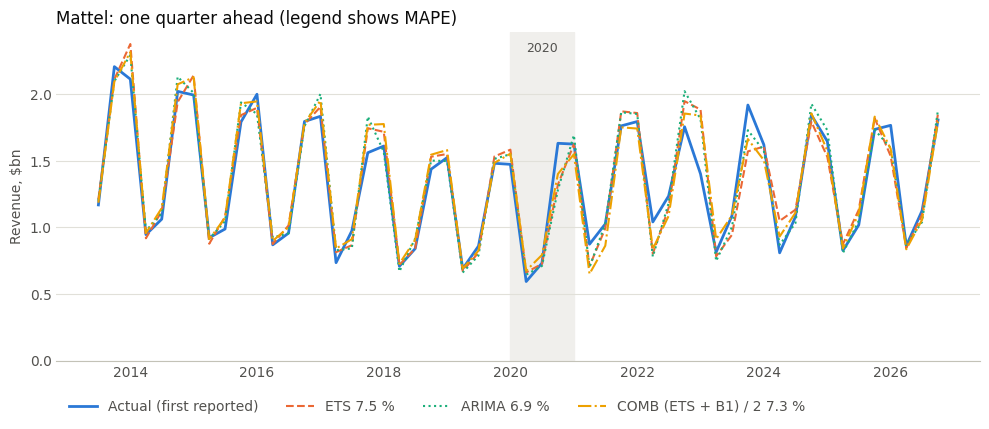

In [14]:
chart("Mattel")

**What this shows:** ETS, ARIMA and COMB nearly overlap. Their forecasts differ by about 4 % in a typical quarter, and their errors move together (correlation 0.83). ARIMA's worst misses are the same pattern-breaking quarters as ETS's: 2022 Q4 (+29 %), 2022 Q1 (−25 %) and 2020 Q3 (−21 %). Better modelling doesn't fix surprises that aren't in the past data.

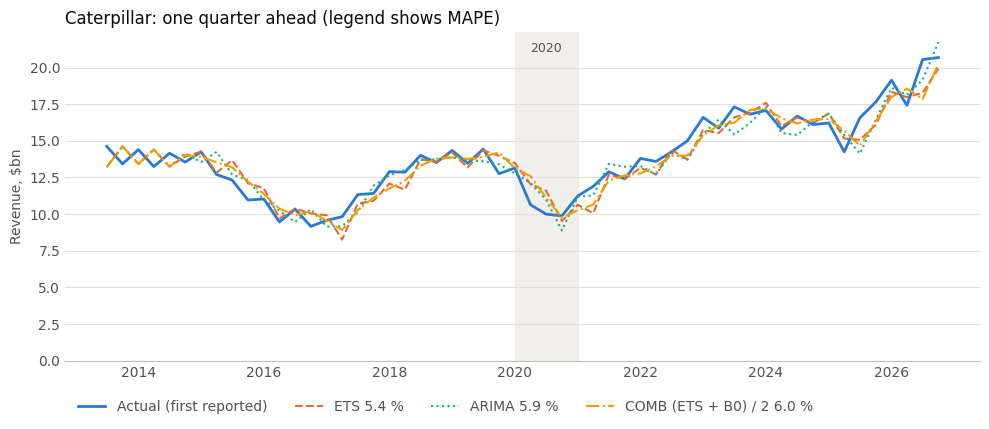

In [15]:
chart("Caterpillar")

**What this shows:** all three methods track the cycle closely one quarter ahead. ARIMA's misses are spread out (worst: 2025 Q2 −15 %, 2020 Q1 +14 %). COMB lost most to ETS in 2015–2016 and early 2020, when averaging in "last quarter" pulled the forecast towards a level revenue had already left.

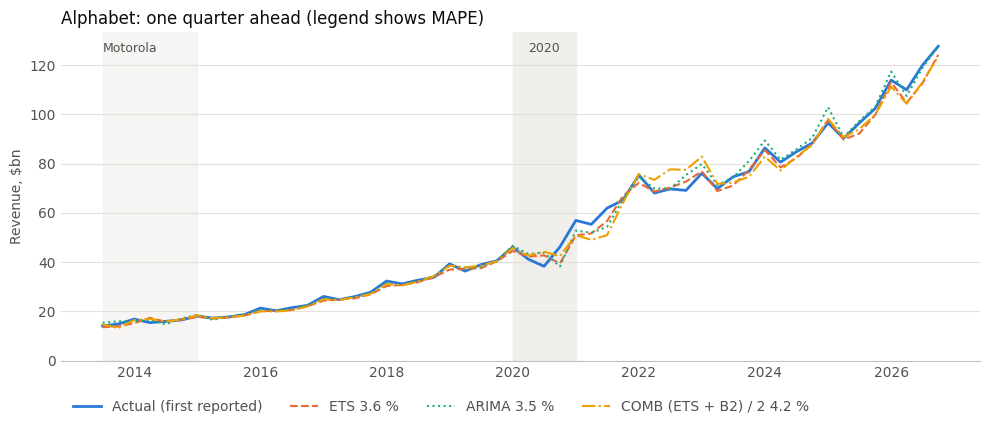

In [16]:
chart("Alphabet")

**What this shows:** ETS and ARIMA hug the actual line; COMB (dash-dot) visibly lifts above it in 2022, because half of it is B2, which over-forecast when Alphabet's growth slowed (2022 Q2: COMB +11 %, ETS +1 %). That's why averaging a good forecast with a clearly weaker one made things worse here. All methods were caught out by the 2020 dip and rebound.

## Summary

| Comparison (main tests) | Mattel | Caterpillar | Alphabet excl. Motorola |
|---|---|---|---|
| h = 1: ARIMA vs ETS | 6.9 vs 7.5 % | 5.9 vs 5.4 % | 3.2 vs 3.4 % |
| h = 1: COMB vs ETS | 7.3 vs 7.5 % | 6.0 vs 5.4 % | 4.2 vs 3.4 % |
| Full year: ARIMA vs best simple rule | 6.7 vs 6.4 % | 8.1 vs 9.2 % | 5.4 vs 7.2 % |
| Full year: COMB vs best simple rule | 6.4 vs 6.4 % | 9.1 vs 9.2 % | 6.1 vs 7.2 % |

All 12 Holm-adjusted p-values are 1.00. **Plainly:** ARIMA is a reasonable alternative to ETS, sometimes slightly better and sometimes slightly worse, but it is much less stable in its choice of model. The 50/50 combination does not help one quarter ahead. For the full-year number, nothing in this session reliably beats the simple FP&A rules. The bars stay as they were: ETS at h = 1, the best simple rule for the full year.